<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 5 Figures — Colab Notebook
**Gauge Theory · Chapter 5: Chiral Symmetry Breaking**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §5.3   | Skyrmion: profile $F(r)$, baryon density, winding number |
| fig02  | §5.5   | WZW term: 5D disk, anomaly matching, $\pi^0\to\gamma\gamma$ |
| fig03  | §5.6   | QCD phase diagram: $\langle\bar\psi\psi\rangle(T)$, $(T,\mu_B)$ diagram, $N_f$ spectrum |

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Middle (baryon density) | **오류** | $B^0=-\tfrac{1}{2\pi^2}\sin^2F\cdot F'$ — 구면 좌표에서 $1/r^2$ 인수 누락. 코드 적분값 1.273 (올바름: 1.000) | $B^0=-\tfrac{1}{2\pi^2}\tfrac{\sin^2F}{r^2}F'$ 로 수정 |
| fig03 | Middle (phase diagram) | **오류** | `r'Nuclear matter\n...'` — r-string 안의 `\n`은 줄바꿈이 아닌 리터럴 `\n` → 텍스트가 한 줄로 표시 | `'Nuclear matter\n'+r'$\mu_B=m_N$'` 로 수정 |
| fig03 | Right (Nf spectrum) | **오류** | Conformal window `axvspan(5.5, 8.5)` — BZ lower bound (Nc=3) ≈ 8. 5.5는 너무 이른 시작 | `axvspan(7.5, 8.5)` + 'onset?' 표기 |
| fig03 | Right (Nf spectrum) | **오류** | `axvline(2.5)` labeled '$N_f=2$', `axvline(3.5)` labeled '$N_f=3$' — 선 위치가 레이블과 불일치 | `axvline(2)`, `axvline(3)` 으로 수정 |
| fig03 | Middle (phase diagram) | **시인성** | 'Dense quark matter', 'Hadronic', 'LHC/RHIC' 텍스트 겹침 | 각 텍스트 위치 분리, 'LHC/RHIC' 단순화 |
| fig03 | Right ($b_0=0$ label) | **시인성** | `r'$b_0=0$\n(IR free)'` — r-string \n 버그로 한 줄 표시 + x축에 너무 가까움 | r-prefix 제거, y위치 올림 |
| fig01 | Left (profile) | **시인성** | BC 레이블 $F(0)=\pi$ / $F(\infty)=0$ 이 axhline과 겹침 | va='bottom'/'top' + 오프셋 조정 |
| fig02 | Right ($\pi^0\to\gamma\gamma$) | **시인성** | 'Nc=3 matches exp!' 주석이 두 줄로 넓음 | 한 줄로 단순화, xytext 위치 조정 |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
import os

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## fig01 · Skyrmion (§5.3)

**Left**: Skyrmion profile function $F(r)$ — kink from $\pi$ to $0$  
**Middle**: Baryon number density $B^0(r) \propto \sin^2 F \cdot F'$  
**Right**: Winding number interpretation — $\pi_3(S^3)=\mathbb{Z}$, $B=1$ map

  saved -> figures/ch05/fig01_skyrmion.png


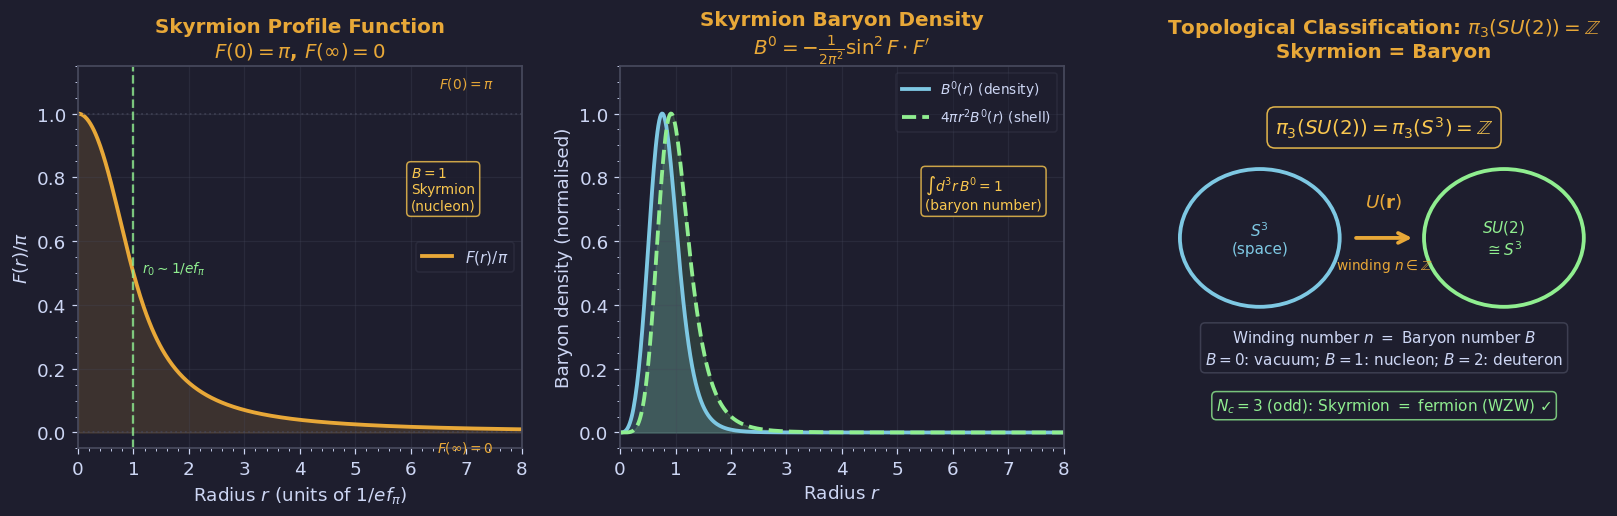

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Skyrmion profile F(r) ────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# Approximate Skyrmion profile: F(r) ~ pi * exp(-r/r0) modified to satisfy BCs
# Better: use arctan-based profile F(r) = 2*arctan((r0/r)^2)
# F(0) = pi, F(inf) = 0, smooth
r = np.linspace(0.001, 8, 500)
r0 = 1.0  # Skyrmion size in units of 1/(e*f_pi)

# Profile: F(r) = 2 arctan((r0/r)^2) -- commonly used analytic approximation
F_r = 2 * np.arctan((r0/r)**2)

ax.fill_between(r, 0, F_r/np.pi, color=AMBER, alpha=0.15)
ax.plot(r, F_r/np.pi, color=AMBER, lw=2.5, label=r'$F(r)/\pi$')

# Boundary conditions
ax.axhline(1, color=EDGE, lw=1.2, ls=':', alpha=0.7)
ax.axhline(0, color=EDGE, lw=1.2, ls=':', alpha=0.7)
ax.text(7.5, 1.07, r'$F(0)=\pi$', ha='right', fontsize=9, color=AMBER, va='bottom')
ax.text(7.5, -0.02, r'$F(\infty)=0$', ha='right', fontsize=9, color=AMBER, va='top')

# Skyrmion size
ax.axvline(r0, color=GREEN, lw=1.5, ls='--', alpha=0.8)
ax.text(r0+0.15, 0.5, r'$r_0\sim 1/ef_\pi$', fontsize=9, color=GREEN)

# Baryon number
ax.text(6, 0.7,
        r'$B=1$'+"\n"+'Skyrmion\n(nucleon)',
        fontsize=9, color=YELLOW,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

ax.set_xlabel(r'Radius $r$ (units of $1/ef_\pi$)')
ax.set_ylabel(r'$F(r)/\pi$')
ax.set_title('Skyrmion Profile Function\n'+r'$F(0)=\pi$, $F(\infty)=0$', color=AMBER)
ax.legend(fontsize=10, labelcolor=FG)
ax.set_xlim(0, 8); ax.set_ylim(-0.05, 1.15)
ax.grid(True, alpha=0.3)

# ── Middle: Baryon density B0(r) ───────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# B0 = -1/(2pi^2) * sin^2(F) * dF/dr
# FIX: Correct B⁰ formula includes 1/r² factor
# B⁰ = -1/(2π²) × sin²(F)/r² × dF/dr
F_prime = np.gradient(F_r, r)
B0 = -1/(2*np.pi**2) * np.sin(F_r)**2 / r**2 * F_prime  # ✓ correct
B0 = np.maximum(B0, 0)  # positive part (B=1)

# Normalise to show shape
B0_norm = B0 / B0.max()

# Also: 4pi r^2 B0 = baryon density per shell
B0_shell = 4*np.pi * r**2 * B0
B0_shell_norm = B0_shell / B0_shell.max()

ax2.fill_between(r, 0, B0_norm, color=BLUE, alpha=0.2)
ax2.plot(r, B0_norm, color=BLUE, lw=2.5, label=r'$B^0(r)$ (density)')
ax2.fill_between(r, 0, B0_shell_norm, color=GREEN, alpha=0.15)
ax2.plot(r, B0_shell_norm, color=GREEN, lw=2.5, ls='--',
         label=r'$4\pi r^2 B^0(r)$ (shell)')

# Integral = 1
ax2.text(5.5, 0.7,
         r'$\int d^3r\, B^0 = 1$'+"\n"+'(baryon number)',
         fontsize=9, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

ax2.set_xlabel(r'Radius $r$')
ax2.set_ylabel('Baryon density (normalised)')
ax2.set_title(
    'Skyrmion Baryon Density\n'
    + r"$B^0 = -\frac{1}{2\pi^2}\sin^2 F \cdot F'$",
    color=AMBER)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(0, 8); ax2.set_ylim(-0.05, 1.15)
ax2.grid(True, alpha=0.3)

# ── Right: Winding number / pi_3(S^3) = Z ─────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.axis('off')

# Draw schematic of S^3 -> SU(2) ~ S^3 map
# Left sphere: physical space S^3 (compactified R^3)
c1 = Circle((0.22, 0.55), 0.18, fill=True, facecolor=BG, edgecolor=BLUE, lw=2.5)
ax3.add_patch(c1)
ax3.text(0.22, 0.55, r'$S^3$'+"\n"+'(space)', ha='center', va='center',
         fontsize=10, color=BLUE, transform=ax3.transAxes)

# Arrow (map)
ax3.annotate('', xy=(0.57, 0.55), xytext=(0.43, 0.55),
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=2.5, mutation_scale=16),
             xycoords='axes fraction', textcoords='axes fraction')
ax3.text(0.50, 0.63, r'$U(\mathbf{r})$', ha='center', fontsize=12,
         color=AMBER, fontweight='bold', transform=ax3.transAxes)
ax3.text(0.50, 0.47, r'winding $n\in\mathbb{Z}$',
         ha='center', fontsize=9, color=AMBER, transform=ax3.transAxes)

# Right sphere: SU(2) ~ S^3 (target)
c2 = Circle((0.77, 0.55), 0.18, fill=True, facecolor=BG, edgecolor=GREEN, lw=2.5)
ax3.add_patch(c2)
ax3.text(0.77, 0.55, r'$SU(2)$'+"\n"+r'$\cong S^3$', ha='center', va='center',
         fontsize=10, color=GREEN, transform=ax3.transAxes)

# Homotopy group
ax3.text(0.50, 0.82,
         r'$\pi_3(SU(2))=\pi_3(S^3)=\mathbb{Z}$',
         ha='center', fontsize=13, color=YELLOW, fontweight='bold',
         transform=ax3.transAxes,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

# Baryon number identification
ax3.text(0.50, 0.22,
         r'Winding number $n$ $=$ Baryon number $B$'+"\n"+
         r'$B=0$: vacuum; $B=1$: nucleon; $B=2$: deuteron',
         ha='center', fontsize=10, color=FG, transform=ax3.transAxes,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=EDGE, alpha=0.8))

# N_c odd = fermion
ax3.text(0.50, 0.10,
         r'$N_c=3$ (odd): Skyrmion $=$ fermion (WZW) '+r'$\checkmark$',
         ha='center', fontsize=10, color=GREEN, transform=ax3.transAxes,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=GREEN, alpha=0.8))

ax3.set_title(r'Topological Classification: $\pi_3(SU(2))=\mathbb{Z}$'+"\nSkyrmion = Baryon", color=AMBER)

plt.tight_layout(pad=1.5)
save('fig01_skyrmion.png', fig)

---
## fig02 · WZW Term & Anomaly Matching (§5.5)

**Left**: 5D disk $M_5$ with boundary $S^4$ — WZW integral geometry  
**Middle**: Anomaly matching diagram — UV quarks = IR pions  
**Right**: $\pi^0\to\gamma\gamma$ vertex strength vs $N_c$ — confirmation of $N_c=3$

  saved -> figures/ch05/fig02_wzw_term.png


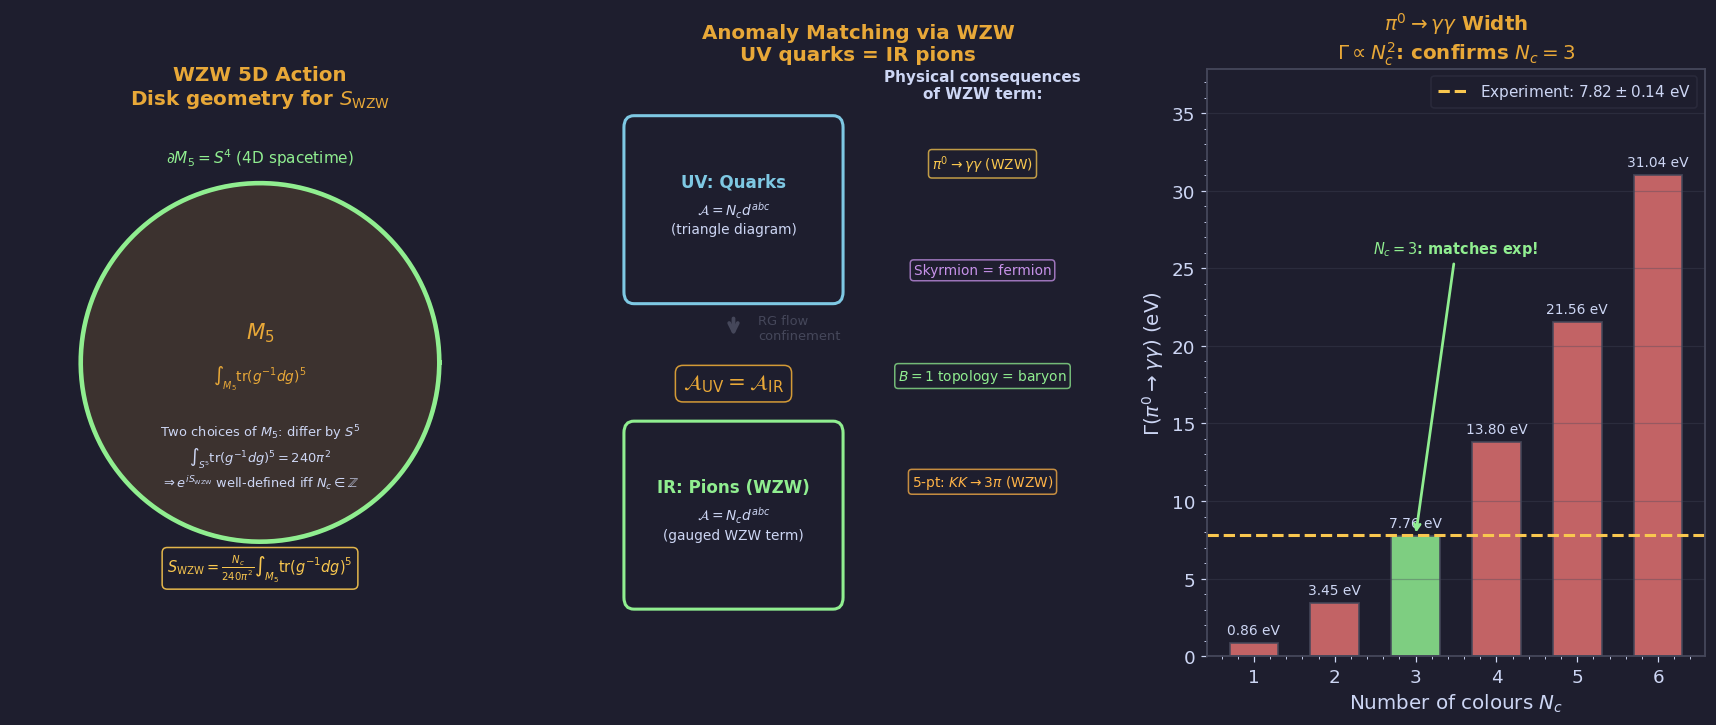

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 7))
fig.patch.set_facecolor(BG)

# ── Left: 5D disk schematic ────────────────────────────────────────────────
# [수정] axis('off') + data 좌표로 통일 (transAxes 혼용 제거)
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')
ax.axis('off')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# [수정] Circle을 data 좌표(transData)로 명시 — 원본은 transAxes 없이 add_patch해서
#        좌표계 불일치로 원이 잘못 그려졌음
disk = Circle((0.5, 0.5), 0.36, fill=True, facecolor=AMBER, alpha=0.15,
              edgecolor=AMBER, lw=2.5, transform=ax.transData, zorder=2)
ax.add_patch(disk)

theta_b = np.linspace(0, 2*np.pi, 300)
ax.plot(0.5 + 0.36*np.cos(theta_b), 0.5 + 0.36*np.sin(theta_b),
        color=GREEN, lw=3, zorder=3)

# [수정] 모든 텍스트를 transData(data 좌표)로 통일
ax.text(0.5, 0.56, r'$M_5$',
        ha='center', va='center', fontsize=14, color=AMBER,
        fontweight='bold', transform=ax.transData, zorder=4)
ax.text(0.5, 0.47, r'$\int_{M_5}\mathrm{tr}(g^{-1}dg)^5$',
        ha='center', va='center', fontsize=9, color=AMBER,
        transform=ax.transData, zorder=4)
ax.text(0.5, 0.90, r'$\partial M_5 = S^4$ (4D spacetime)',
        ha='center', fontsize=10, color=GREEN, transform=ax.transData)
ax.text(0.5, 0.25,
        r'Two choices of $M_5$: differ by $S^5$' + '\n' +
        r'$\int_{S^5}\mathrm{tr}(g^{-1}dg)^5 = 240\pi^2$' + '\n' +
        r'$\Rightarrow e^{iS_{\rm WZW}}$ well-defined iff $N_c\in\mathbb{Z}$',
        ha='center', fontsize=8.5, color=FG, transform=ax.transData, zorder=4)
ax.text(0.5, 0.08,
        r'$S_{\rm WZW} = \frac{N_c}{240\pi^2}\int_{M_5}\mathrm{tr}(g^{-1}dg)^5$',
        ha='center', fontsize=9.5, color=YELLOW, transform=ax.transData,
        bbox=dict(boxstyle='round,pad=0.35', facecolor=BG, edgecolor=YELLOW, alpha=0.9),
        zorder=5)

ax.set_title('WZW 5D Action\nDisk geometry for $S_{\\rm WZW}$', color=AMBER)

# ── Middle: Anomaly matching ───────────────────────────────────────────────
# [수정] 모든 patch와 텍스트를 ax2.transAxes로 일관되게 통일
#        원본은 FancyBboxPatch에 transform 없음 + annotate에 xycoords='axes fraction'
#        + text에 transform=ax2.transAxes 를 혼용 → 박스/텍스트/화살표 위치 불일치
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.axis('off')
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)

uv_box = FancyBboxPatch((0.05, 0.62), 0.40, 0.28,
                         boxstyle='round,pad=0.02', facecolor=BG,
                         edgecolor=BLUE, linewidth=2,
                         transform=ax2.transAxes, zorder=2)  # [수정] transform 명시
ax2.add_patch(uv_box)
ax2.text(0.25, 0.80, 'UV: Quarks', ha='center', fontsize=11,
         color=BLUE, fontweight='bold', transform=ax2.transAxes)
ax2.text(0.25, 0.72, r'$\mathcal{A}=N_c d^{abc}$' + '\n' + '(triangle diagram)',
         ha='center', fontsize=9, color=FG, transform=ax2.transAxes)

# [수정] annotate xycoords='axes fraction'으로 통일 (원본은 default data 좌표)
ax2.annotate('', xy=(0.25, 0.54), xytext=(0.25, 0.58),
             arrowprops=dict(arrowstyle='->', color=EDGE, lw=2.5, mutation_scale=14),
             xycoords='axes fraction', textcoords='axes fraction')
ax2.text(0.30, 0.54, 'RG flow\nconfinement',
         fontsize=8.5, color=EDGE, transform=ax2.transAxes, ha='left')

ir_box = FancyBboxPatch((0.05, 0.10), 0.40, 0.28,
                         boxstyle='round,pad=0.02', facecolor=BG,
                         edgecolor=GREEN, linewidth=2,
                         transform=ax2.transAxes, zorder=2)  # [수정] transform 명시
ax2.add_patch(ir_box)
ax2.text(0.25, 0.28, 'IR: Pions (WZW)', ha='center', fontsize=11,
         color=GREEN, fontweight='bold', transform=ax2.transAxes)
ax2.text(0.25, 0.20, r'$\mathcal{A}=N_c d^{abc}$' + '\n' + '(gauged WZW term)',
         ha='center', fontsize=9, color=FG, transform=ax2.transAxes)

ax2.text(0.25, 0.455,
         r'$\mathcal{A}_{\rm UV} = \mathcal{A}_{\rm IR}$',
         ha='center', fontsize=14, color=AMBER, fontweight='bold',
         transform=ax2.transAxes,
         bbox=dict(boxstyle='round,pad=0.35', facecolor=BG, edgecolor=AMBER, alpha=0.9))

ax2.text(0.75, 0.95, 'Physical consequences\nof WZW term:',
         ha='center', fontsize=10, color=FG, fontweight='bold',
         transform=ax2.transAxes)

for i, (txt, col) in enumerate([
    (r'$\pi^0\to\gamma\gamma$ (WZW)', YELLOW),
    ('Skyrmion = fermion', PURPLE),
    (r'$B=1$ topology = baryon', GREEN),
    (r'5-pt: $KK\to 3\pi$ (WZW)', ORANGE),
]):
    ax2.text(0.75, 0.83 - i*0.18, txt,
             ha='center', fontsize=9, color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.25', facecolor=BG, edgecolor=col, alpha=0.75))

ax2.set_title('Anomaly Matching via WZW\nUV quarks = IR pions', color=AMBER)

# ── Right: pi0 -> gamma gamma width vs Nc ─────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

Nc_vals = np.arange(1, 7)
Gamma_scaled = 7.76 * (Nc_vals / 3)**2   # Nc=6 → 31.04 eV

bar_cols = [RED if nc != 3 else GREEN for nc in Nc_vals]
bars = ax3.bar(Nc_vals, Gamma_scaled, color=bar_cols, edgecolor=EDGE,
               lw=1.2, alpha=0.85, width=0.6)

# [수정] ylim을 데이터 최대값 기준으로 설정 (원본 ylim=16은 Nc≥5 bar를 잘라냄)
y_max = Gamma_scaled.max()
ax3.set_ylim(0, y_max * 1.22)

ax3.axhline(7.82, color=YELLOW, lw=2, ls='--',
            label=r'Experiment: $7.82\pm 0.14$ eV')

# [수정] bar 값 레이블 offset을 y_max 대비 비율로 계산해 항상 bar 위에 표시
for bar, val in zip(bars, Gamma_scaled):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + y_max * 0.018,
             f'{val:.2f} eV', ha='center', fontsize=9, color=FG)

ax3.annotate(r'$N_c=3$: matches exp!',
             xy=(3, 7.76), xytext=(3.5, 26),
             fontsize=9.5, color=GREEN, fontweight='bold', ha='center',
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.8))

ax3.set_xlabel(r'Number of colours $N_c$', fontsize=13)
ax3.set_ylabel(r'$\Gamma(\pi^0\to\gamma\gamma)$ (eV)', fontsize=13)
ax3.set_title(r'$\pi^0\to\gamma\gamma$ Width' + '\n' +
              r'$\Gamma\propto N_c^2$: confirms $N_c=3$', color=AMBER)
ax3.set_xticks(Nc_vals)
ax3.legend(fontsize=10)
ax3.grid(True, axis='y', alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig02_wzw_term.png', fig)

---
## fig03 · QCD Phase Diagram (§5.6)

**Left**: Chiral condensate $\langle\bar\psi\psi\rangle(T)$ — melting at $T_c$  
**Middle**: QCD phase diagram in $(T, \mu_B)$ plane  
**Right**: Meson spectrum vs $N_f$ — approach to conformal window

  saved -> figures/ch05/fig03_phase_diagram.png


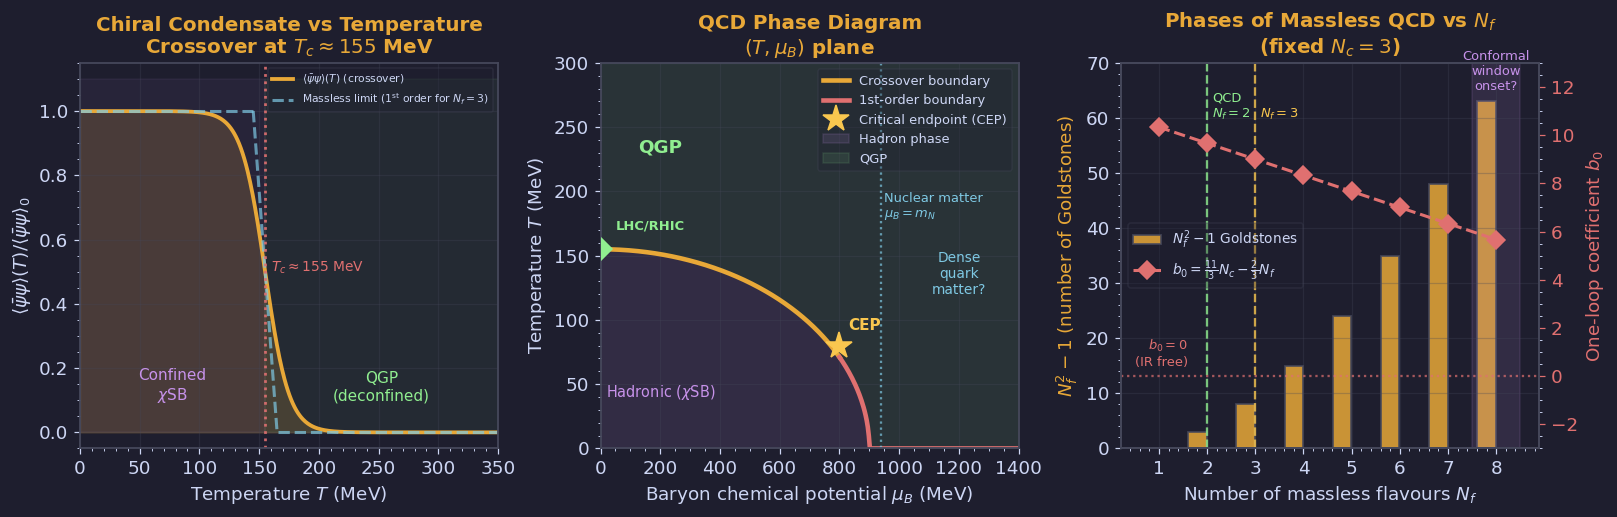

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: condensate vs T ──────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

T = np.linspace(0, 350, 500)  # MeV
Tc = 155   # MeV (crossover temperature)
cond0 = 1.0  # normalised

# Approximate condensate: smooth crossover with hyperbolic tangent
width = 20  # MeV (crossover width)
cond_T = cond0 / 2 * (1 - np.tanh((T - Tc) / width))

ax.fill_between(T, 0, cond_T, color=AMBER, alpha=0.18)
ax.plot(T, cond_T, color=AMBER, lw=2.5, label=r'$\langle\bar\psi\psi\rangle(T)$ (crossover)')

# First-order transition (massless quarks)
T_firstorder = np.concatenate([T[T<Tc-10], T[T>Tc+10]])
cond_fo_low  = cond0 * np.ones(len(T[T<Tc-10]))
cond_fo_high = np.zeros(len(T[T>Tc+10]))
ax.plot(T[T<Tc-10], cond_fo_low,  color=BLUE, lw=2, ls='--', alpha=0.7)
ax.plot(T[T>Tc+10], cond_fo_high, color=BLUE, lw=2, ls='--', alpha=0.7,
        label=r'Massless limit ($1^{\rm st}$ order for $N_f=3$)')
ax.plot([Tc-10, Tc+10], [cond0, 0], color=BLUE, lw=2, ls='--', alpha=0.7)

# Tc marker
ax.axvline(Tc, color=RED, lw=1.8, ls=':', alpha=0.9)
ax.text(Tc+5, 0.5, r'$T_c\approx 155$ MeV', fontsize=9, color=RED)

# Region labels
ax.fill_betweenx([0, 1.1], 0, Tc, color=PURPLE, alpha=0.06)
ax.fill_betweenx([0, 1.1], Tc, 350, color=GREEN, alpha=0.06)
ax.text(Tc/2, 0.1, 'Confined\n'+r'$\chi$SB', ha='center', fontsize=10, color=PURPLE)
ax.text((Tc+350)/2, 0.1, 'QGP\n(deconfined)', ha='center', fontsize=10, color=GREEN)

ax.set_xlabel(r'Temperature $T$ (MeV)')
ax.set_ylabel(r'$\langle\bar\psi\psi\rangle(T)/\langle\bar\psi\psi\rangle_0$')
ax.set_title('Chiral Condensate vs Temperature\n'+r'Crossover at $T_c\approx 155$ MeV', color=AMBER)
ax.legend(loc="upper right", fontsize=7, labelcolor=FG)
ax.set_xlim(0, 350); ax.set_ylim(-0.05, 1.15)
ax.grid(True, alpha=0.3)

# ── Middle: QCD phase diagram (T, mu_B) ────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

mu_B = np.linspace(0, 1400, 400)  # MeV
T_arr = np.linspace(0, 300, 400)

# Phase boundary: T_c(mu_B) decreasing with mu_B
Tc_mu = Tc * np.sqrt(np.maximum(1 - (mu_B/900)**2, 0))

# Critical endpoint at mu_B ~ 800-1000 MeV, T ~ 50-100 MeV
mu_CEP = 800
T_CEP  = 80

# Phase boundary splits at CEP:
# crossover for mu_B < mu_CEP, first-order for mu_B > mu_CEP
mu_cross = mu_B[mu_B <= mu_CEP]
T_cross  = Tc * np.sqrt(np.maximum(1 - (mu_cross/900)**2, 0))
mu_fo    = mu_B[mu_B >= mu_CEP]
T_fo     = Tc * np.sqrt(np.maximum(1 - (mu_fo/900)**2, 0))

ax2.plot(mu_cross, T_cross, color=AMBER, lw=3, ls='-',
         label='Crossover boundary')
ax2.plot(mu_fo, T_fo, color=RED, lw=3, ls='-',
         label='1st-order boundary')

# Critical endpoint
ax2.plot(mu_CEP, T_CEP, '*', color=YELLOW, ms=18, zorder=6,
         label='Critical endpoint (CEP)')
ax2.text(mu_CEP+30, T_CEP+12, 'CEP', fontsize=10, color=YELLOW, fontweight='bold')

# Fill phases
ax2.fill_between(mu_B, 0, Tc_mu, color=PURPLE, alpha=0.12, label='Hadron phase')
ax2.fill_between(mu_B, Tc_mu, 300, color=GREEN, alpha=0.10, label='QGP')

# Nuclear matter
ax2.axvline(938, color=BLUE, lw=1.5, ls=':', alpha=0.7)
ax2.text(950, 180, 'Nuclear matter\n'+r'$\mu_B=m_N$', fontsize=8.5, color=BLUE)

# LHC and RHIC markers
ax2.plot(0, 155, 'D', color=GREEN, ms=10, zorder=5)
ax2.text(50, 170, 'LHC/RHIC', fontsize=8.5, color=GREEN, fontweight='bold')

# Labels
ax2.text(200, 40, r'Hadronic ($\chi$SB)', ha='center', fontsize=9.5, color=PURPLE)
ax2.text(200, 230, 'QGP', ha='center', fontsize=12, color=GREEN, fontweight='bold')
ax2.text(1200, 120, 'Dense\nquark\nmatter?', ha='center', fontsize=9, color=BLUE)

ax2.set_xlabel(r'Baryon chemical potential $\mu_B$ (MeV)')
ax2.set_ylabel(r'Temperature $T$ (MeV)')
ax2.set_title('QCD Phase Diagram\n'+r'$(T, \mu_B)$ plane', color=AMBER)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper right')
ax2.set_xlim(0, 1400); ax2.set_ylim(0, 300)
ax2.grid(True, alpha=0.3)

# ── Right: Spectrum vs Nf ──────────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

Nf_vals = np.arange(1, 9)

# Number of Goldstone bosons: Nf^2 - 1
n_goldstone = Nf_vals**2 - 1

# b0 = 11/3*Nc - 2/3*Nf for Nc=3
Nc = 3
b0_vals = (11/3)*Nc - (2/3)*Nf_vals

# Conformal window starts around Nf ~ 12 (b0 changes sign above Nf=16.5)
# Plot b0 (scaled) and Nf^2-1

ax3_twin = ax3.twinx()
ax3_twin.set_facecolor(BG)

ax3.bar(Nf_vals - 0.2, n_goldstone, width=0.38, color=AMBER, alpha=0.85,
        edgecolor=EDGE, lw=1.2, label=r'$N_f^2-1$ Goldstones')
ax3_twin.plot(Nf_vals, b0_vals, 'D--', color=RED, lw=2, ms=8,
              label=r'$b_0 = \frac{11}{3}N_c-\frac{2}{3}N_f$')

ax3_twin.axhline(0, color=RED, lw=1.5, ls=':', alpha=0.7)
ax3_twin.text(1.6, 0.4, '$b_0=0$\n(IR free)', ha='right', fontsize=8.5, color=RED)

# Conformal window region
# FIX: BZ lower bound for Nc=3 is Nf≈8, not 5.5
ax3.axvspan(7.5, 8.5, color=PURPLE, alpha=0.12)
ax3.text(8.0, 65, 'Conformal\nwindow\nonset?', ha='center', fontsize=8.5, color=PURPLE)

# Physical QCD
# FIX: Physical QCD Nf=2 line at x=2, not 2.5
ax3.axvline(2, color=GREEN, lw=1.5, ls='--', alpha=0.8)
ax3.text(2.1, 60, 'QCD\n$N_f=2$', fontsize=8.5, color=GREEN)
# FIX: Physical QCD Nf=3 line at x=3, not 3.5
ax3.axvline(3, color=YELLOW, lw=1.5, ls='--', alpha=0.8)
ax3.text(3.1, 60, '$N_f=3$', fontsize=8.5, color=YELLOW)

ax3.set_xlabel(r'Number of massless flavours $N_f$')
ax3.set_ylabel(r'$N_f^2-1$ (number of Goldstones)', color=AMBER)
ax3_twin.set_ylabel(r'One-loop coefficient $b_0$', color=RED)
ax3_twin.tick_params(axis='y', colors=RED)

ax3.set_title(r'Phases of Massless QCD vs $N_f$'+"\n"+r'(fixed $N_c=3$)', color=AMBER)
ax3.set_xticks(Nf_vals)
ax3.set_ylim(0, 70)
ax3_twin.set_ylim(-3, 13)
ax3.grid(True, alpha=0.3)

lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3_twin.get_legend_handles_labels()
ax3.legend(lines1+lines2, labels1+labels2, fontsize=9, labelcolor=FG, loc='center left')

plt.tight_layout(pad=1.5)
save('fig03_phase_diagram.png', fig)

---
## Download figures

In [5]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch05_figures', 'zip', '.', 'figures')
files.download('gauge_ch05_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_skyrmion.png`    | $F(r)$ profile / baryon density / $\pi_3(S^3)=\mathbb{Z}$ | ☐ |
| `fig02_wzw_term.png`    | 5D disk / anomaly matching / $\pi^0\to\gamma\gamma$ vs $N_c$ | ☐ |
| `fig03_phase_diagram.png`| Condensate vs $T$ / QCD phase diagram / Goldstones vs $N_f$ | ☐ |